# Module 18 — Multi-agents avec LangChain et LangGraph

> **Objectif** : orchestrer plusieurs étapes et plusieurs agents spécialisés de façon **fiable** : graphes d'état, routage, superviseur, boucle de relecture, exécution parallèle, points de contrôle et **humain dans la boucle**. On code d'abord un **mini-moteur de graphe d'état** (une centaine de lignes) pour comprendre exactement ce que fait LangGraph, on y implémente les grands patrons avec des agents simulés et on mesure leur coût, puis on écrit les mêmes systèmes avec **LangChain 1.x** et **LangGraph 1.x**. On termine par un tour des autres frameworks et par les critères pour choisir… ou pour **ne pas** faire de multi-agents.

| | |
|---|---|
| **Durée estimée** | 3 h 30 |
| **Prérequis** | Modules 15 (agents, outils, MCP), 16 (RAG), 17 (KG-RAG) |
| **Librairies** | `numpy`, `matplotlib` ; `langchain`, `langgraph`, `langchain[anthropic]` (sections 6–8) |

> ⚙️ Comme au module 15, les sections 2 à 5 utilisent des **agents simulés** (règles déterministes) pour que tout s'exécute sans clé d'API ; la mécanique d'orchestration est réelle. Les sections 6 à 8 donnent le code LangChain / LangGraph pour de vrais modèles.
>
> 🗓️ API vérifiées en octobre 2026 (LangChain 1.x, LangGraph 1.x). En LangChain 1.0, `create_agent` (dans `langchain.agents`) remplace l'ancien `create_react_agent` de `langgraph.prebuilt`.

**Plan**

1. Pourquoi des graphes, et quand plusieurs agents ?
2. Un mini-moteur de graphe d'état
3. Patron 1 : routeur
4. Patron 2 : superviseur et agents spécialisés ; patron 3 : rédaction et relecture
5. Patron 4 : parallélisme (map-reduce), points de contrôle et humain dans la boucle
6. LangChain 1.x : modèles, outils, `create_agent`
7. LangGraph : `StateGraph`, arêtes conditionnelles, persistance, interruptions
8. Multi-agents avec LangGraph : sous-agents comme outils, transferts, `Send`
9. Le paysage des frameworks, observabilité, et les pièges du multi-agents
10. Récapitulatif et exercices

In [1]:
import json
import re
import time
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})

## 1. Pourquoi des graphes, et quand plusieurs agents ?

La boucle d'agent du module 15 est un graphe à deux nœuds (« modèle » ↔ « outils »). Dès qu'un système grandit, on veut **contrôler** le flux : imposer une étape de vérification, router selon le type de question, paralléliser des recherches, reprendre après une interruption, demander une validation humaine avant une action. Un **graphe d'état** rend ce flux **explicite** :
- un **état** partagé (un dictionnaire typé) qui circule ;
- des **nœuds** (fonctions : un appel de LLM, un outil, du code) qui lisent l'état et renvoient des **mises à jour** ;
- des **arêtes** fixes ou **conditionnelles** (une fonction choisit le nœud suivant selon l'état) ;
- des **réducteurs** qui disent comment fusionner une mise à jour (remplacer, ou ajouter à une liste) ;
- un **point de contrôle** (*checkpoint*) sauvegardé après chaque étape : on peut reprendre, rejouer, inspecter, ou attendre un humain.

**Plusieurs agents** = plusieurs LLM (ou plusieurs prompts / jeux d'outils) aux **rôles distincts**. Avantages : chaque agent a un contexte plus court et plus focalisé, des outils limités (moindre privilège, module 15), un prompt spécialisé ; on peut paralléliser. Coûts : plus d'appels, plus de latence, et surtout de l'information **perdue entre agents** (chacun ne voit qu'une partie du contexte). On y revient en section 9.

## 2. Un mini-moteur de graphe d'état

Tout LangGraph tient conceptuellement dans ce qui suit. On l'écrit pour ne plus jamais le considérer comme une boîte noire.

In [2]:
START, END = "__start__", "__end__"


class Interrupt(Exception):
    """Raised by a node to pause the graph and wait for human input."""
    def __init__(self, payload):
        super().__init__(str(payload)); self.payload = payload


class Send:
    """Fan-out: run `node` with a private input (map step of map-reduce)."""
    def __init__(self, node, arg):
        self.node, self.arg = node, arg


class MiniGraph:
    def __init__(self, reducers=None):
        self.nodes, self.edges, self.cond = {}, {}, {}
        self.reducers = reducers or {}                      # key -> function(old, new) ; default: overwrite

    def add_node(self, name, fn):
        self.nodes[name] = fn; return self

    def add_edge(self, a, b):
        self.edges[a] = b; return self

    def add_conditional_edges(self, a, router):
        self.cond[a] = router; return self

    def _merge(self, state, update):
        for k, v in (update or {}).items():
            state[k] = self.reducers[k](state.get(k), v) if k in self.reducers else v
        return state

    def _next(self, node, state):
        if node in self.cond:
            return self.cond[node](state)                   # a node name, END, or a list of Send
        return self.edges.get(node, END)

    def compile(self, checkpointer=None, max_steps=25):
        graph = self

        class App:
            def __init__(self):
                self.checkpoints = checkpointer if checkpointer is not None else {}
                self.trace = []

            def invoke(self, state, thread_id="default", resume=None):
                if resume is not None:                      # continue a paused thread
                    saved = self.checkpoints[thread_id]
                    state, node = dict(saved["state"]), saved["next"]
                    state["__resume__"] = resume
                else:
                    state, node = dict(state), graph._next(START, state)
                for step in range(max_steps):
                    if node == END:
                        state.pop("__resume__", None)
                        self.checkpoints[thread_id] = {"state": dict(state), "next": END}
                        return state
                    if isinstance(node, list):              # fan-out (Send): run each branch, merge with reducers
                        for s in node:
                            self.trace.append(s.node)
                            graph._merge(state, graph.nodes[s.node]({**state, **s.arg}))
                        node = graph.edges.get(node[0].node, END)
                        continue
                    self.trace.append(node)
                    try:
                        update = graph.nodes[node](state)
                    except Interrupt as it:
                        self.checkpoints[thread_id] = {"state": dict(state), "next": node, "interrupt": it.payload}
                        return {**state, "__interrupt__": it.payload}
                    state = graph._merge(state, update)
                    state.pop("__resume__", None)
                    self.checkpoints[thread_id] = {"state": dict(state), "next": graph._next(node, state)}
                    node = self.checkpoints[thread_id]["next"]
                raise RuntimeError("max_steps reached: probable infinite loop")

        return App()


append = lambda old, new: (old or []) + (new if isinstance(new, list) else [new])    # the "add messages" reducer

Les mêmes notions existent dans LangGraph : `StateGraph`, `add_node`, `add_edge`, `add_conditional_edges`, des réducteurs déclarés avec `Annotated[list, operator.add]`, `compile(checkpointer=…)`, `interrupt()` et `Command(resume=…)`, `Send` (section 7).

### Les agents simulés et leurs outils

Trois spécialistes : un agent **documentaire** (recherche BM25 dans des notes), un agent **graphe** (petite base de faits structurés, comme au module 17), un agent **rédacteur**. Plus un **relecteur**. Chaque « appel de LLM » est compté, pour comparer les coûts des patrons.

In [3]:
NOTES = {
    "protocole-cdr3": "Protocole v2.1 : la CDR3 est délimitée entre la 2e cystéine (104) et le motif J-Trp/Phe-Gly-X-Gly (118-121).",
    "protocole-qc": "Protocole v2.1 : chaque annotation est vérifiée par un second annotateur ; les désaccords sont consignés.",
    "orf-definition": "Un allèle ORF (open reading frame) a un cadre de lecture ouvert mais une anomalie de signal d'épissage ou de séquences de recombinaison.",
    "lora-note": "LoRA n'entraîne qu'une mise à jour de faible rang des poids ; utile pour adapter un modèle avec peu de mémoire.",
}
FACTS = [("DEMO-IGHV1-05", "locus", "IGH"), ("DEMO-IGHV1-05", "allele_ORF", 1), ("DEMO-IGHV2-01", "locus", "IGH"),
         ("DEMO-IGHV2-01", "allele_ORF", 0), ("DEMO-IGHV3-06", "locus", "IGH"), ("DEMO-IGHV3-06", "allele_ORF", 2),
         ("DEMO-IGKV1-02", "locus", "IGK"), ("DEMO-IGKV1-02", "allele_ORF", 1)]

CALLS = Counter()                                          # "LLM calls" per agent


def llm_call(agent):
    CALLS[agent] += 1


STOP = {"le", "la", "les", "de", "des", "du", "d", "un", "une", "et", "sur", "que", "quelle", "est", "dans", "qu", "ce", "dit"}


def tokens(text):
    return set(re.findall(r"\w+", text.lower())) - STOP


def search_notes(query, k=2):
    """Keyword-overlap retrieval; keeps only passages scoring above half the best score."""
    q = tokens(query)
    scored = sorted(((len(q & tokens(t)), d, t) for d, t in NOTES.items()), reverse=True)
    best = scored[0][0]
    return [(d, t) for sc, d, t in scored[:k] if sc > 0 and sc > best / 2]


def query_facts(locus):
    genes = [s for s, p, o in FACTS if p == "locus" and o == locus]
    return {g: next(o for s, p, o in FACTS if s == g and p == "allele_ORF") for g in genes}

## 3. Patron 1 : le routeur

Un premier nœud **classe** la question et l'envoie vers **un** traitement spécialisé. C'est un *workflow* (le chemin est choisi une fois), très économique. Le classement peut être fait par un petit modèle ou par sortie structurée d'un LLM (section 7).

In [4]:
def router_node(state):
    llm_call("router")
    q = state["question"].lower()
    needs_docs = any(w in q for w in ["protocole", "définition", "qu'est-ce", "règle", "lora"])
    needs_kg = any(w in q for w in ["combien", "liste", "nombre", "quels gènes"])
    route = "both" if needs_docs and needs_kg else "docs" if needs_docs else "kg" if needs_kg else "direct"
    return {"route": route, "log": f"router -> {route}"}


def docs_node(state):
    llm_call("docs_agent")
    hits = search_notes(state["question"])
    return {"evidence": [f"[{d}] {t}" for d, t in hits], "log": f"docs: {len(hits)} passages"}


def kg_node(state):
    llm_call("kg_agent")
    locus = next((l for l in ["IGH", "IGK", "IGL", "TRB"] if l.lower() in state["question"].lower()), "IGH")
    res = query_facts(locus)
    return {"evidence": [f"[kg:{locus}] allèles ORF par gène : {res} (total {sum(res.values())})"], "log": f"kg: locus {locus}"}


def writer_node(state):
    llm_call("writer")
    ev = state.get("evidence", [])
    draft = ("D'après les sources : " + " ".join(ev)) if ev else "Je n'ai pas de source pour répondre."
    return {"answer": draft, "log": "writer: draft"}


def route_after_router(state):
    return {"docs": "docs", "kg": "kg", "both": [Send("docs", {}), Send("kg", {})], "direct": "writer"}[state["route"]]

router_graph = (MiniGraph(reducers={"evidence": append, "log": append})
                .add_node("router", router_node).add_node("docs", docs_node).add_node("kg", kg_node).add_node("writer", writer_node)
                .add_conditional_edges(START, lambda s: "router")
                .add_conditional_edges("router", route_after_router)
                .add_edge("docs", "writer").add_edge("kg", "writer").add_edge("writer", END))

app = router_graph.compile()
for q in ["Que dit le protocole sur la CDR3 ?", "Combien d'allèles ORF dans le locus IGH ?",
          "Combien d'allèles ORF dans IGK, et quelle est la définition d'un ORF ?"]:
    CALLS.clear(); app.trace.clear()
    out = app.invoke({"question": q})
    print(f"Q: {q}\n   path: {' -> '.join(app.trace)} | LLM calls: {sum(CALLS.values())}\n   {out['answer'][:170]}\n")

Q: Que dit le protocole sur la CDR3 ?
   path: router -> docs -> writer | LLM calls: 3
   D'après les sources : [protocole-cdr3] Protocole v2.1 : la CDR3 est délimitée entre la 2e cystéine (104) et le motif J-Trp/Phe-Gly-X-Gly (118-121).

Q: Combien d'allèles ORF dans le locus IGH ?
   path: router -> kg -> writer | LLM calls: 3
   D'après les sources : [kg:IGH] allèles ORF par gène : {'DEMO-IGHV1-05': 1, 'DEMO-IGHV2-01': 0, 'DEMO-IGHV3-06': 2} (total 3)

Q: Combien d'allèles ORF dans IGK, et quelle est la définition d'un ORF ?
   path: router -> docs -> kg -> writer | LLM calls: 4
   D'après les sources : [orf-definition] Un allèle ORF (open reading frame) a un cadre de lecture ouvert mais une anomalie de signal d'épissage ou de séquences de recombina



## 4. Patron 2 : superviseur ; patron 3 : rédaction et relecture

### Le superviseur

Un agent **superviseur** décide, à chaque tour, quel spécialiste appeler ensuite (ou de terminer), en fonction de ce qui manque dans l'état. Plus flexible qu'un routeur (plusieurs étapes, ordre adaptatif), mais chaque décision coûte un appel de LLM.

### La boucle rédaction / relecture (*evaluator-optimizer*)

Un **relecteur** vérifie le brouillon selon des critères explicites (ici : chaque affirmation est sourcée, la réponse n'est pas trop longue) et renvoie au rédacteur avec des remarques, dans la limite d'un nombre de tours. C'est l'un des patrons les plus rentables quand les critères de qualité sont **vérifiables**.

In [5]:
def supervisor_node(state):
    llm_call("supervisor")
    q, ev = state["question"].lower(), " ".join(state.get("evidence", []))
    want_docs = any(w in q for w in ["protocole", "définition", "règle"]) and "[protocole" not in ev and "[orf" not in ev
    want_kg = any(w in q for w in ["combien", "nombre", "liste"]) and "[kg:" not in ev
    nxt = "docs" if want_docs else "kg" if want_kg else "writer" if not state.get("answer") else "FINISH"
    return {"next": nxt, "log": f"supervisor -> {nxt}"}


def careful_writer_node(state):
    llm_call("writer")
    ev = state.get("evidence", [])
    feedback = state.get("feedback")
    if feedback and "citation" in feedback:                  # the reviewer asked for explicit citations
        body = " ".join(f"{e.split('] ', 1)[1]} [{e[1:].split(']')[0]}]" for e in ev)
    else:
        body = " ".join(e.split("] ", 1)[1] for e in ev)      # first draft: forgets the citations
    return {"answer": body or "Pas de source.", "revision": state.get("revision", 0) + 1, "log": "writer: draft"}


def reviewer_node(state):
    llm_call("reviewer")
    ans = state["answer"]
    problems = []
    if not re.search(r"\[[\w:\-]+\]", ans):
        problems.append("ajoute une citation [source] à chaque affirmation")
    if len(ans.split()) > 120:
        problems.append("raccourcis à moins de 120 mots")
    return {"feedback": "; ".join(problems) or None, "log": f"reviewer: {'OK' if not problems else problems}"}


def after_review(state):
    if state.get("feedback") and state.get("revision", 0) < 3:
        return "writer"
    return END

sup_graph = (MiniGraph(reducers={"evidence": append, "log": append})
             .add_node("supervisor", supervisor_node).add_node("docs", docs_node).add_node("kg", kg_node)
             .add_node("writer", careful_writer_node).add_node("reviewer", reviewer_node)
             .add_conditional_edges(START, lambda s: "supervisor")
             .add_conditional_edges("supervisor", lambda s: {"FINISH": END}.get(s["next"], s["next"]))
             .add_edge("docs", "supervisor").add_edge("kg", "supervisor")
             .add_edge("writer", "reviewer").add_conditional_edges("reviewer", after_review))

app2 = sup_graph.compile()
CALLS.clear()
out = app2.invoke({"question": "Combien d'allèles ORF dans IGH, et quelle est la définition d'un ORF ?"})
print("path:", " -> ".join(app2.trace))
print("log :", out["log"])
print("calls per agent:", dict(CALLS), "| total:", sum(CALLS.values()))
print("final answer:", out["answer"])

path: supervisor -> docs -> supervisor -> kg -> supervisor -> writer -> reviewer -> writer -> reviewer
log : ['supervisor -> docs', 'docs: 1 passages', 'supervisor -> kg', 'kg: locus IGH', 'supervisor -> writer', 'writer: draft', "reviewer: ['ajoute une citation [source] à chaque affirmation']", 'writer: draft', 'reviewer: OK']
calls per agent: {'supervisor': 3, 'docs_agent': 1, 'kg_agent': 1, 'writer': 2, 'reviewer': 2} | total: 9
final answer: Un allèle ORF (open reading frame) a un cadre de lecture ouvert mais une anomalie de signal d'épissage ou de séquences de recombinaison. [orf-definition] allèles ORF par gène : {'DEMO-IGHV1-05': 1, 'DEMO-IGHV2-01': 0, 'DEMO-IGHV3-06': 2} (total 3) [kg:IGH]


Lis la trace : le superviseur a appelé l'agent documentaire **puis** l'agent graphe, puis le rédacteur ; le relecteur a **refusé** le premier brouillon (pas de citations) et l'a renvoyé ; le second brouillon est accepté. Le résultat est meilleur (chaque affirmation est sourcée), mais il a fallu **9 appels**, contre 4 pour le routeur sur la même question. Sur le graphe ci-dessous, les arêtes en tirets sont conditionnelles : c'est là que se loge toute la « décision », donc tout le risque.

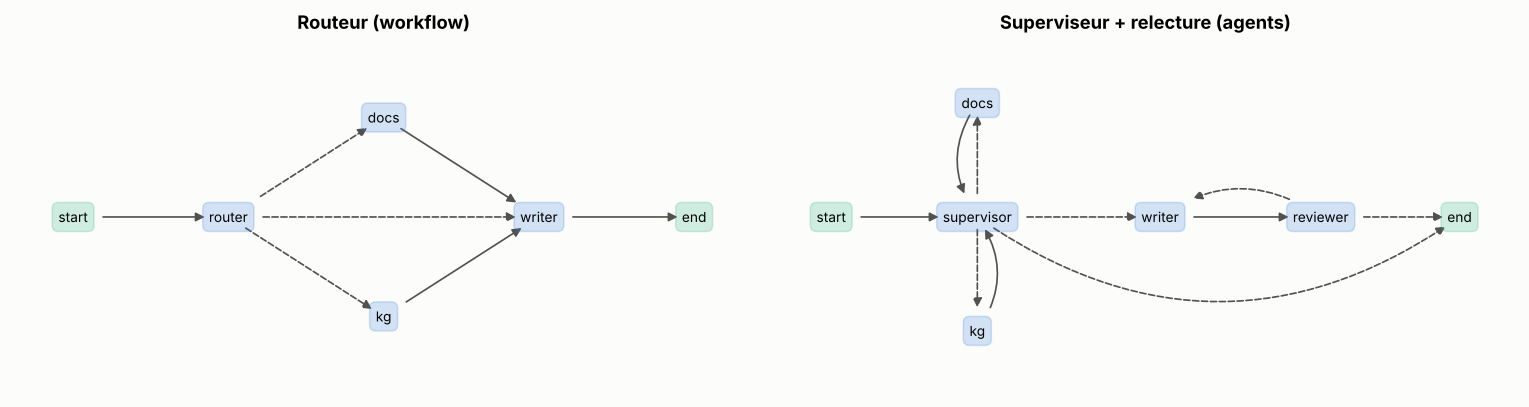

In [6]:
LAYOUTS = {
    "router": {START: (0, 0), "router": (2, 0), "docs": (4, 1), "kg": (4, -1), "writer": (6, 0), END: (8, 0)},
    "supervisor": {START: (0, 0), "supervisor": (2, 0), "docs": (2, 1.4), "kg": (2, -1.4),
                   "writer": (4.5, 0), "reviewer": (6.7, 0), END: (8.6, 0)},
}
POSSIBLE = {"router": ["docs", "kg", "writer"], "supervisor": ["docs", "kg", "writer", END], "reviewer": ["writer", END]}


from matplotlib.patches import FancyArrowPatch


def draw_graph(g, layout, title, ax):
    """Drawing of a MiniGraph: solid = fixed edge, dashed = conditional edge."""
    boxes = {}
    for n, (x, y) in layout.items():
        col = PALETTE[2] if n in (START, END) else PALETTE[0]
        boxes[n] = ax.text(x, y, n.strip("_"), ha="center", va="center", fontsize=9,
                           bbox=dict(boxstyle="round,pad=0.45", fc=col, alpha=0.2, ec=col))
    edges = [(a, b, False) for a, b in g.edges.items()]
    edges += [(START, next(iter(g.nodes)), False)]
    edges += [(a, b, True) for a in g.cond if a in POSSIBLE for b in POSSIBLE[a]]
    for a, b, dashed in edges:
        curved = (a, b) in {("supervisor", END), ("reviewer", "writer"), ("docs", "supervisor"), ("kg", "supervisor")}
        ax.add_patch(FancyArrowPatch(layout[a], layout[b], patchA=boxes[a].get_bbox_patch(), patchB=boxes[b].get_bbox_patch(),
                                     arrowstyle="-|>", mutation_scale=12, color="#52514e", lw=1.1,
                                     ls="--" if dashed else "-", connectionstyle=f"arc3,rad={0.35 if curved else 0}"))
    xs, ys = zip(*layout.values())
    ax.set_xlim(min(xs) - 0.8, max(xs) + 0.8); ax.set_ylim(min(ys) - 0.8, max(ys) + 0.8)
    ax.axis("off"); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
draw_graph(router_graph, LAYOUTS["router"], "Routeur (workflow)", axes[0])
draw_graph(sup_graph, LAYOUTS["supervisor"], "Superviseur + relecture (agents)", axes[1])
plt.tight_layout(); plt.show()

## 5. Parallélisme, points de contrôle, humain dans la boucle

### Map-reduce avec `Send`

Pour traiter **plusieurs sous-tâches indépendantes** (résumer 3 documents, interroger 4 loci), on « éclate » l'état en branches parallèles puis on fusionne grâce au réducteur. Dans le routeur ci-dessus, la route `both` utilisait déjà ce mécanisme.

In [7]:
def plan_node(state):
    llm_call("planner")
    return {"loci": ["IGH", "IGK"], "log": "planner: 2 loci"}


def per_locus_node(state):
    llm_call("kg_agent")
    res = query_facts(state["locus"])
    return {"evidence": [f"[kg:{state['locus']}] {sum(res.values())} allèle(s) ORF"], "log": f"kg {state['locus']}"}

mr = (MiniGraph(reducers={"evidence": append, "log": append})
      .add_node("plan", plan_node).add_node("per_locus", per_locus_node).add_node("writer", writer_node)
      .add_conditional_edges(START, lambda s: "plan")
      .add_conditional_edges("plan", lambda s: [Send("per_locus", {"locus": l}) for l in s["loci"]])
      .add_edge("per_locus", "writer").add_edge("writer", END))
app3 = mr.compile()
out = app3.invoke({"question": "Compare les ORF de IGH et IGK"})
print(" -> ".join(app3.trace)); print(out["answer"])

plan -> per_locus -> per_locus -> writer
D'après les sources : [kg:IGH] 3 allèle(s) ORF [kg:IGK] 1 allèle(s) ORF


### Points de contrôle et humain dans la boucle

Le moteur sauvegarde l'état après **chaque** nœud, par **fil** (*thread*) de conversation. Un nœud peut **interrompre** l'exécution pour demander une validation : l'état est sauvegardé, l'application rend la main à l'utilisateur, puis **reprend** exactement au même endroit avec sa réponse. C'est indispensable avant toute action à effet de bord (module 15) et pour les processus longs.

In [8]:
SENT = []


def draft_report_node(state):
    llm_call("writer")
    return {"report": "Rapport : 3 allèles ORF dans IGH (DEMO-IGHV1-05 : 1, DEMO-IGHV3-06 : 2).", "log": "draft report"}


def approval_node(state):
    if "__resume__" not in state:                          # first visit: pause and ask the human
        raise Interrupt({"question": "Envoyer ce rapport à l'équipe ?", "report": state["report"]})
    return {"approved": bool(state["__resume__"]), "log": f"human said {state['__resume__']}"}


def send_node(state):
    if state.get("approved"):
        SENT.append(state["report"])
        return {"log": "report sent"}
    return {"log": "report NOT sent"}

hitl = (MiniGraph(reducers={"log": append})
        .add_node("draft", draft_report_node).add_node("approval", approval_node).add_node("send", send_node)
        .add_conditional_edges(START, lambda s: "draft").add_edge("draft", "approval").add_edge("approval", "send").add_edge("send", END))
store = {}                                                  # the checkpointer (in memory here; a database in production)
app4 = hitl.compile(checkpointer=store)

res = app4.invoke({"question": "rapport ORF"}, thread_id="thread-42")
print("PAUSED ->", res["__interrupt__"])
print("checkpoint saved for thread-42, next node:", store["thread-42"]["next"])
# ... later (minutes or days), possibly in another process that reloads the checkpointer:
res = app4.invoke(None, thread_id="thread-42", resume=True)
print("RESUMED ->", res["log"], "| sent:", SENT)

PAUSED -> {'question': "Envoyer ce rapport à l'équipe ?", 'report': 'Rapport : 3 allèles ORF dans IGH (DEMO-IGHV1-05 : 1, DEMO-IGHV3-06 : 2).'}
checkpoint saved for thread-42, next node: approval
RESUMED -> ['draft report', 'human said True', 'report sent'] | sent: ['Rapport : 3 allèles ORF dans IGH (DEMO-IGHV1-05 : 1, DEMO-IGHV3-06 : 2).']


### Comparer les coûts

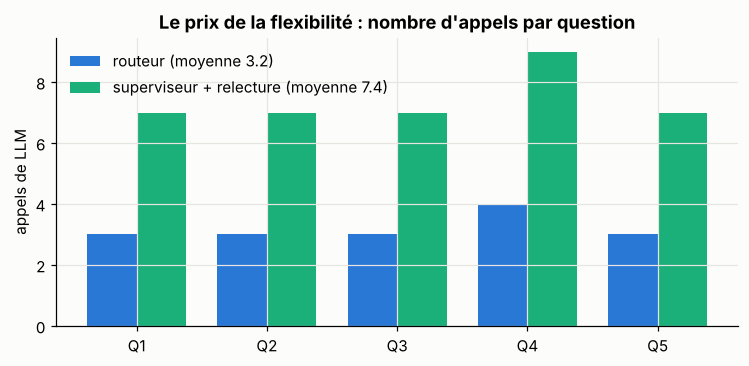

In [9]:
QUESTIONS = ["Que dit le protocole sur la CDR3 ?", "Combien d'allèles ORF dans le locus IGH ?",
             "Quelle est la définition d'un ORF ?", "Combien d'allèles ORF dans IGK, et quelle est la définition d'un ORF ?",
             "Que dit le protocole sur le contrôle qualité ?"]
costs = {}
for name, graph in [("routeur", router_graph), ("superviseur + relecture", sup_graph)]:
    calls = []
    for q in QUESTIONS:
        CALLS.clear()
        graph.compile().invoke({"question": q})
        calls.append(sum(CALLS.values()))
    costs[name] = calls
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(QUESTIONS))
for k, (name, c) in enumerate(costs.items()):
    ax.bar(x + (k - 0.5) * 0.38, c, 0.38, color=PALETTE[k * 2], label=f"{name} (moyenne {np.mean(c):.1f})")
ax.set_xticks(x); ax.set_xticklabels([f"Q{i + 1}" for i in x]); ax.set_ylabel("appels de LLM"); ax.legend()
ax.set_title("Le prix de la flexibilité : nombre d'appels par question")
plt.show()

Le superviseur avec relecture coûte un peu plus du double du routeur à chaque question, même les plus simples : il paie systématiquement ses décisions (3 appels du superviseur) et le premier brouillon refusé. Avec un vrai modèle, l'écart en **tokens** est plus grand encore, car chaque appel relit un contexte qui grossit. La flexibilité n'est rentable que si elle améliore assez la qualité sur **tes** questions : mesure-le sur ton jeu d'évaluation avant de choisir.

## 6. LangChain 1.x : modèles, outils, `create_agent`

LangChain fournit des **interfaces communes** (modèles de chat, messages, outils, documents, *retrievers*) et, depuis la version 1.0, une fonction **`create_agent`** qui construit la boucle d'agent du module 15 (exécutée par le moteur de LangGraph).

In [ ]:
# pip install -U langchain langgraph "langchain[anthropic]"     (export ANTHROPIC_API_KEY=...)
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain.agents import create_agent

model = init_chat_model("anthropic:claude-sonnet-5-5", temperature=0)      # same call for "openai:...", "ollama:..." etc.


@tool
def search_protocol(query: str) -> str:
    """Search the lab's annotation protocol notes. Returns passages with their ids."""
    return "\n".join(f"[{d}] {t}" for d, t in search_notes(query))


@tool
def count_orf_alleles(locus: str) -> str:
    """Count ORF alleles per gene for a locus (IGH, IGK, IGL, TRB) in the knowledge graph."""
    return json.dumps(query_facts(locus.upper()))


agent = create_agent(model=model, tools=[search_protocol, count_orf_alleles],
                     system_prompt="Tu es un assistant d'annotation. Cite les identifiants des sources entre crochets.")
result = agent.invoke({"messages": [{"role": "user", "content": "Combien d'allèles ORF dans IGH, et qu'est-ce qu'un ORF ?"}]})
for m in result["messages"]:
    print(type(m).__name__, ":", str(m.content)[:150])

**Sortie structurée** : pour qu'un nœud renvoie un objet exploitable (une route, une liste d'entités), on décrit le format par un modèle Pydantic.

In [ ]:
from typing import Literal
from pydantic import BaseModel, Field


class Route(BaseModel):
    """Which specialist should handle the question."""
    route: Literal["docs", "kg", "both", "direct"]
    reason: str = Field(description="one short sentence")

router_llm = model.with_structured_output(Route)
print(router_llm.invoke("Combien d'allèles ORF dans IGK, et quelle est la définition d'un ORF ?"))

## 7. LangGraph : `StateGraph`, arêtes conditionnelles, persistance, interruptions

Le routeur de la section 3, en LangGraph, avec un vrai modèle pour le routage et la rédaction :

In [ ]:
import operator
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send


class State(TypedDict):
    question: str
    route: str
    evidence: Annotated[list[str], operator.add]          # reducer: branch outputs are appended
    answer: str


def lg_router(state: State):
    return {"route": router_llm.invoke(state["question"]).route}


def lg_docs(state: State):
    return {"evidence": [f"[{d}] {t}" for d, t in search_notes(state["question"])]}


def lg_kg(state: State):
    return {"evidence": [f"[kg:IGH] {json.dumps(query_facts('IGH'))}"]}


def lg_writer(state: State):
    sources = "\n".join(state.get("evidence", []))
    msg = model.invoke(f"Réponds en citant les sources [id].\n\nSources :\n{sources}\n\nQuestion : {state['question']}")
    return {"answer": msg.content}


def lg_route(state: State):
    if state["route"] == "both":
        return [Send("docs", state), Send("kg", state)]   # parallel branches
    return {"docs": "docs", "kg": "kg", "direct": "writer"}[state["route"]]


builder = StateGraph(State)
builder.add_node("router", lg_router)
builder.add_node("docs", lg_docs)
builder.add_node("kg", lg_kg)
builder.add_node("writer", lg_writer)
builder.add_edge(START, "router")
builder.add_conditional_edges("router", lg_route, ["docs", "kg", "writer"])
builder.add_edge("docs", "writer")
builder.add_edge("kg", "writer")
builder.add_edge("writer", END)
graph = builder.compile()

out = graph.invoke({"question": "Combien d'allèles ORF dans IGH, et qu'est-ce qu'un ORF ?"})
print(out["answer"])
for update in graph.stream({"question": "Que dit le protocole sur la CDR3 ?"}, stream_mode="updates"):
    print(update)                                        # one dict per node execution: ideal for a UI or for debugging

### Persistance et humain dans la boucle

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver      # production: a SQLite / Postgres checkpointer
from langgraph.types import interrupt, Command


class ReportState(TypedDict):
    report: str
    approved: bool


def draft(state: ReportState):
    return {"report": model.invoke("Rédige un rapport de 2 phrases sur les allèles ORF de IGH : " + json.dumps(query_facts("IGH"))).content}


def approval(state: ReportState):
    decision = interrupt({"question": "Envoyer ce rapport ?", "report": state["report"]})   # pauses here
    return {"approved": bool(decision)}


def send(state: ReportState):
    if state["approved"]:
        print("SENDING:", state["report"])
    return {}


b = StateGraph(ReportState)
b.add_node("draft", draft); b.add_node("approval", approval); b.add_node("send", send)
b.add_edge(START, "draft"); b.add_edge("draft", "approval"); b.add_edge("approval", "send"); b.add_edge("send", END)
report_graph = b.compile(checkpointer=InMemorySaver())

config = {"configurable": {"thread_id": "thread-42"}}
first = report_graph.invoke({"report": "", "approved": False}, config=config)
print(first["__interrupt__"])                              # what the human must answer
resumed = report_graph.invoke(Command(resume=True), config=config)   # same thread_id: resumes inside approval()
print(report_graph.get_state(config).values)              # inspect the saved state at any time

> ⚠️ Un nœud interrompu est **ré-exécuté depuis son début** à la reprise : tout ce qui précède `interrupt()` dans ce nœud s'exécute deux fois. Place les effets de bord **après** l'interruption, ou dans un nœud séparé (comme `send` ci-dessus).

## 8. Multi-agents avec LangGraph

Trois façons de composer des agents, de la plus simple à la plus libre.

### 8.1 Des sous-agents comme outils (superviseur)

Le plus simple et souvent le meilleur : chaque spécialiste est un agent complet (`create_agent`) exposé au superviseur **comme un outil**. Le superviseur garde le contrôle et le contexte global ; chaque sous-agent reçoit une tâche précise et renvoie un résultat condensé.

In [ ]:
docs_agent = create_agent(model, tools=[search_protocol],
                          system_prompt="Tu cherches dans le protocole et réponds en 3 phrases maximum avec les ids des sources.")
kg_agent = create_agent(model, tools=[count_orf_alleles],
                        system_prompt="Tu interroges le graphe de connaissances et renvoies des chiffres exacts.")


@tool
def ask_docs_agent(task: str) -> str:
    """Delegate a question about the annotation protocol or definitions to the documentation specialist."""
    return docs_agent.invoke({"messages": [{"role": "user", "content": task}]})["messages"][-1].content


@tool
def ask_kg_agent(task: str) -> str:
    """Delegate a counting or listing question about genes and alleles to the knowledge-graph specialist."""
    return kg_agent.invoke({"messages": [{"role": "user", "content": task}]})["messages"][-1].content


supervisor = create_agent(model, tools=[ask_docs_agent, ask_kg_agent],
                          system_prompt="Tu coordonnes deux spécialistes. Découpe la question, délègue, puis synthétise "
                                        "une réponse unique en conservant les citations.")
print(supervisor.invoke({"messages": [{"role": "user", "content": "Combien d'ORF dans IGH, et qu'est-ce qu'un ORF ?"}]})["messages"][-1].content)

### 8.2 Transferts (*handoffs*) avec `Command`

Un nœud peut à la fois **mettre à jour l'état** et **choisir le nœud suivant** en renvoyant un `Command` : c'est ainsi qu'un agent « passe la main » à un autre (par exemple un agent d'accueil qui transfère à un spécialiste).

In [ ]:
from typing import Literal
from langgraph.types import Command


class ChatState(TypedDict):
    question: str
    answer: str


def triage(state: ChatState) -> Command[Literal["kg_specialist", "docs_specialist"]]:
    target = "kg_specialist" if any(w in state["question"].lower() for w in ["combien", "liste"]) else "docs_specialist"
    return Command(goto=target, update={"answer": f"(transféré à {target})"})


def kg_specialist(state: ChatState):
    return {"answer": kg_agent.invoke({"messages": [{"role": "user", "content": state["question"]}]})["messages"][-1].content}


def docs_specialist(state: ChatState):
    return {"answer": docs_agent.invoke({"messages": [{"role": "user", "content": state["question"]}]})["messages"][-1].content}


h = StateGraph(ChatState)
h.add_node("triage", triage); h.add_node("kg_specialist", kg_specialist); h.add_node("docs_specialist", docs_specialist)
h.add_edge(START, "triage"); h.add_edge("kg_specialist", END); h.add_edge("docs_specialist", END)
print(h.compile().invoke({"question": "Combien d'allèles ORF dans IGK ?"})["answer"])

### 8.3 Graphes imbriqués et équipes

Un graphe compilé est lui-même un nœud possible : on peut composer des **équipes** (une équipe « recherche » et une équipe « rédaction », chacune avec son superviseur) sous un superviseur général. Utile pour de gros systèmes, mais chaque niveau ajoute des appels et des pertes d'information : à réserver aux cas où la séparation est vraiment justifiée.

## 9. Le paysage des frameworks, observabilité, et les pièges du multi-agents

### Les frameworks

| Framework | Style | Points forts |
|---|---|---|
| **LangGraph** (+ LangChain) | graphes d'état explicites | contrôle fin, persistance, interruptions, streaming ; très utilisé en production |
| **LlamaIndex** | centré sur les données et le RAG (workflows à événements) | ingestion, index, requêtes sur documents |
| **Pydantic AI** | agents typés, validation Pydantic | sorties structurées sûres, style « Python pur » |
| **smolagents** (Hugging Face) | agents qui écrivent du **code** pour agir | minimaliste, bon avec des modèles ouverts ; exige un bac à sable |
| **CrewAI** | équipes de rôles (« crews ») | prototypage rapide de scénarios multi-rôles |
| **AutoGen / Microsoft Agent Framework** | conversations entre agents | patrons de dialogue multi-agents |
| **SDK d'agents des fournisseurs** (Claude Agent SDK, OpenAI Agents SDK, Google ADK) | boucle d'agent du fournisseur, outils intégrés | rapide à démarrer ; plus lié à un fournisseur |

**Conseil** : apprendre d'abord la boucle et les patrons (ce cours), puis choisir l'outil le plus **simple** qui couvre le besoin. Pour beaucoup de projets de recherche, une boucle de 50 lignes (module 15) ou un `StateGraph` de 5 nœuds suffit.

### Observer et déboguer

Un système multi-agents est inexploitable sans **traces** : quel nœud, quelle entrée, quelle sortie, quels outils, combien de tokens, combien de temps. Outils : **LangSmith** (intégré à LangChain / LangGraph), **Langfuse** (open source), ou l'instrumentation **OpenTelemetry** standard. Garde aussi les traces pour construire ton **jeu d'évaluation** à partir de cas réels.

### Les pièges du multi-agents

| Piège | Explication | Parade |
|---|---|---|
| **Coût** | chaque agent relit du contexte ; Anthropic indiquait en 2025 que son système de recherche multi-agents consommait de l'ordre de 15 fois plus de tokens qu'une conversation simple | réserver le multi-agents aux tâches à forte valeur, parallélisables |
| **Contexte fragmenté** | un sous-agent ne voit pas les décisions implicites des autres ; les résultats deviennent incohérents (un argument central de « Don't Build Multi-Agents », Cognition, 2025) | transmettre des consignes **complètes** et un contexte partagé ; préférer un agent unique quand les étapes sont très dépendantes |
| **Erreurs composées** | une erreur précoce se propage et s'amplifie | points de vérification (relecteur, validations programmatiques), limites de tours |
| **Boucles infinies** | deux agents se renvoient la balle | `max_steps`, compteurs dans l'état, conditions d'arrêt explicites |
| **Sécurité** | plus d'outils et de contenus non fiables = plus de surface d'injection (module 15) | moindre privilège **par agent**, validation humaine des actions |
| **Évaluation** | le comportement émerge des interactions | évaluer de bout en bout **et** par agent, avec des traces |

> 🎯 **Quand le multi-agents vaut le coup** : sous-tâches **indépendantes** et **parallélisables** (recherche large sur plusieurs sources), outils ou expertises **très différents** (un agent SPARQL, un agent documentaire, un agent qui exécute du code en bac à sable), ou besoin de **séparer les droits**. Quand les étapes sont séquentielles et fortement couplées, un agent unique bien outillé est généralement meilleur.

## 10. Récapitulatif

| Notion | À retenir |
|---|---|
| Graphe d'état | état typé + nœuds + arêtes (conditionnelles) + réducteurs + checkpoints |
| Routeur | 1 classification puis 1 traitement : économique, prévisible |
| Superviseur | décide à chaque tour ; flexible ; plus d'appels |
| Relecture | critères explicites, renvoi au rédacteur, nombre de tours limité |
| Map-reduce | `Send` pour les branches, réducteur pour fusionner |
| Persistance | checkpoint par `thread_id` ; reprise, inspection, rejeu |
| Humain dans la boucle | `interrupt()` puis `Command(resume=…)` ; effets de bord après l'interruption |
| LangChain 1.x | `init_chat_model`, `@tool`, `create_agent`, `with_structured_output` |
| LangGraph | `StateGraph`, `add_conditional_edges`, `InMemorySaver`, `Command`, `Send`, `stream` |
| Multi-agents | sous-agents comme outils d'abord ; transferts ; mesurer le coût ; traces |

### 🏋️ Exercices

1. **Relecteur plus exigeant.** Ajoute au relecteur une vérification de **fidélité** (la fonction `citation_support` du module 16). Combien de tours supplémentaires en moyenne ?
2. **Budget.** Ajoute à l'état un compteur d'appels et une arête conditionnelle qui force la fin (avec la meilleure réponse disponible) au-delà d'un budget.
3. **Reprise après panne.** Sauvegarde le `store` du mini-moteur en JSON après chaque nœud, « tue » l'exécution au milieu, recharge et reprends.
4. **LangGraph réel.** Implémente le graphe superviseur + relecture de la section 4 avec LangGraph et un vrai modèle, branche les outils du module 17 via MCP, et compare le nombre d'appels avec la version routeur sur 10 questions.
5. **Agent unique vs multi-agents.** Sur les mêmes 10 questions, compare un agent unique (`create_agent` avec tous les outils) au superviseur : justesse, appels, latence. Lequel choisirais-tu, et pourquoi ?

<details><summary>Indications</summary>

2. Un champ `calls` avec un réducteur additif, incrémenté par chaque nœud ; la fonction de routage teste `state["calls"] >= budget`.
5. Sur des questions courtes et couplées, l'agent unique gagne souvent en coût et en cohérence ; le superviseur se justifie quand les sous-questions sont indépendantes et que chaque spécialiste a des outils et des consignes très différents.
</details>

---

**Fin de la partie III.** Tu as maintenant toute la chaîne d'une application LLM moderne : un modèle adapté à ta tâche (module 14), capable d'appeler des outils exposés par MCP (module 15), d'aller chercher des connaissances dans des documents (module 16) et dans un graphe de connaissances (module 17), le tout orchestré de façon contrôlée et vérifiable (module 18).